# بررسی محیط کاری — گام ۱
**آزمایشگاه هوش مصنوعی | گروه ۳ | امیرحسین نوروزی | پروژه: تشخیص ارقام دست‌نویس**

هدف این نوت‌بوک (بند ۳ گام ۱): ثبت **نسخه پایتون**، **مسیر اجرای پایتون** و **نسخه کتابخانه‌های مورد استفاده**
(NumPy، Matplotlib و بقیه) + یک تست کوچک برای اطمینان از کارکرد محیط.

اجرا در VS Code: `Ctrl+Shift+P` ← **Python: Select Interpreter** ← محیط `ailab`، سپس **Run All**.
اجرا در Jupyter: `jupyter notebook` ← باز کردن همین فایل ← **Kernel ▸ Restart & Run All**.

In [1]:
import platform
import sys

print("python version   :", sys.version.split()[0])
print("full version     :", sys.version.replace(chr(10), " "))
print("executable path  :", sys.executable)
print("prefix (env)     :", sys.prefix)
print("platform         :", platform.platform())
print("machine / cpu    :", platform.machine(), "-", platform.processor() or "n/a")

python version   : 3.13.5
full version     : 3.13.5 (main, Aug 10 2026, 12:06:59) [GCC 14.2.0]
executable path  : /home/amirho3in/.venvs/ailab/bin/python
prefix (env)     : /home/amirho3in/.venvs/ailab
platform         : Linux-6.12.113+deb13-amd64-x86_64-with-glibc2.41
machine / cpu    : x86_64 - n/a


## نسخه کتابخانه‌ها
هر کتابخانه‌ای که در پروژه استفاده می‌شود این‌جا چک می‌شود. کتابخانه‌های اختیاری
(`torch`، `sklearn`) اگر نصب نباشند خطا نمی‌دهند، فقط `MISSING` چاپ می‌شود.

In [2]:
from importlib import import_module

REQUIRED = ["numpy", "matplotlib", "pandas"]
OPTIONAL = ["torch", "torchvision", "sklearn", "scipy", "jupyter", "IPython"]

rows = []
for name in REQUIRED + OPTIONAL:
    try:
        module = import_module(name)
        rows.append((name, getattr(module, "__version__", "?"), getattr(module, "__file__", "")))
    except Exception:
        rows.append((name, "MISSING", "-"))

width = max(len(n) for n, _, _ in rows)
print("== versions " + "=" * (width + 18))
for name, version, path in rows:
    flag = "required" if name in REQUIRED else "optional"
    print(f"{name:<{width}}  {version:<22} {flag}")

missing = [n for n, v, _ in rows if v == "MISSING" and n in REQUIRED]
print("\nresult:", "ALL REQUIRED LIBS OK" if not missing else f"MISSING -> {missing}")

== versions =============================
numpy        2.5.4                  required
matplotlib   3.11.2                 required
pandas       3.1.0                  required
torch        MISSING                optional
torchvision  MISSING                optional
sklearn      1.9.1                  optional
scipy        1.18.1                 optional
jupyter      ?                      optional
IPython      9.18.0                 optional

result: ALL REQUIRED LIBS OK


## مسیر نصب بسته‌ها
برای اطمینان از اینکه بسته‌ها داخل همان محیط `ailab` نصب شده‌اند (نه پایتون سیستم):

In [3]:
import site

import numpy

print("numpy from :", numpy.__file__)
print("search paths used by this kernel:")
for p in site.getsitepackages():
    print("   ", p)

numpy from : /home/amirho3in/.venvs/ailab/lib/python3.13/site-packages/numpy/__init__.py
search paths used by this kernel:
    /home/amirho3in/.venvs/ailab/lib/python3.13/site-packages
    /home/amirho3in/.venvs/ailab/local/lib/python3.13/dist-packages
    /home/amirho3in/.venvs/ailab/lib/python3/dist-packages
    /home/amirho3in/.venvs/ailab/lib/python3.13/dist-packages


## ۱) تست NumPy — میانگین و انحراف معیار
همان کاری که در کد کلاس برای خلاصه‌سازی نتایج ۱۰۰ اجرا لازم بود.

In [4]:
import numpy as np

x = np.array([2, 4, 4, 4, 5, 5, 7, 9], dtype=float)
print("mean       :", x.mean())
print("std        :", x.std())
print("sem (std/√n):", x.std() / np.sqrt(len(x)))
print("rng check  :", np.random.default_rng(0).random(3), "  (seed=0 باید همیشه یکسان باشد)")
assert np.allclose(np.random.default_rng(7).random(4), np.random.default_rng(7).random(4))
print("reproducible seeds: OK")

mean       : 5.0
std        : 2.0
sem (std/√n): 0.7071067811865475
rng check  : [0.63696169 0.26978671 0.04097352]   (seed=0 باید همیشه یکسان باشد)
reproducible seeds: OK


## ۲) تست Matplotlib — رسم و ذخیره نمودار
اگر این سلول بدون خطا اجرا شود، خروجی نمودار گام‌های بعدی (سردرگمی، دقت، مقایسه روش‌ها) قابل تولید است.

backend: module://matplotlib_inline.backend_inline


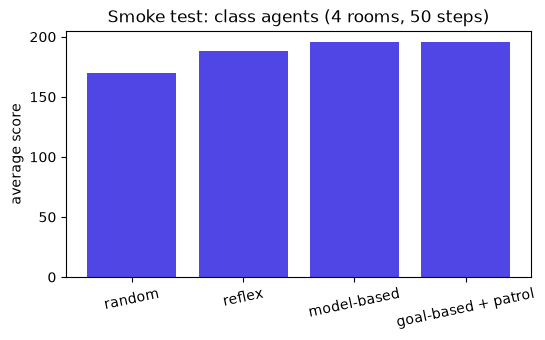

saved -> results/check_env_plot.png


In [5]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt

print("backend:", matplotlib.get_backend())

scores = {"random": 169.98, "reflex": 187.78, "model-based": 195.34, "goal-based + patrol": 195.34}
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(list(scores), list(scores.values()), color="#4f46e5")
ax.set_ylabel("average score")
ax.set_title("Smoke test: class agents (4 rooms, 50 steps)")
ax.tick_params(axis="x", rotation=12)

out = Path("results")
out.mkdir(exist_ok=True)
fig.savefig(out / "check_env_plot.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved ->", out / "check_env_plot.png")

## ۳) تست پردازش تصویر (نزدیک به پروژه ما)
یک تصویر مصنوعی `28×28` می‌سازیم و شکل/بازه داده را بررسی می‌کنیم؛ در گام ۲ همین بررسی روی داده واقعی انجام می‌شود.

shape      : (28, 28)
dtype      : float64
min / max  : 0.0 / 1.0
mean pixel : 0.3389
non-zero   : 29.7%


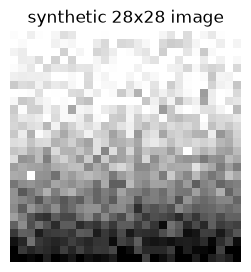

In [6]:
img = (np.linspace(0, 1, 28 * 28) ** 2).reshape(28, 28)
img = np.clip(img + 0.1 * np.random.default_rng(0).standard_normal(img.shape), 0, 1)

print("shape      :", img.shape)
print("dtype      :", img.dtype)
print("min / max  :", round(float(img.min()), 3), "/", round(float(img.max()), 3))
print("mean pixel :", round(float(img.mean()), 4))
print("non-zero   :", f"{(img > 0.5).mean() * 100:.1f}%")

fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(img, cmap="gray_r")
ax.set_title("synthetic 28x28 image")
ax.axis("off")
plt.show()

## ۴) محدودیت سخت‌افزار
ریسک ۳ در `notes/risks.md`: آموزش شبکه عصبی روی CPU یا سهمیه ابر. این سلول منابع را ثبت می‌کند.

In [7]:
import os

print("cpu cores  :", os.cpu_count())
try:
    print("memory GB  :", round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3, 1))
except ValueError:
    print("memory GB  : n/a (windows)")

try:
    import torch

    print("cuda       :", torch.cuda.is_available())
except ImportError:
    print("cuda       : torch not installed yet (گام ۴ به بعد)")

cpu cores  : 12
memory GB  : 15.5
cuda       : torch not installed yet (گام ۴ به بعد)


## جمع‌بندی محیط

| مورد | مقدار |
|---|---|
| پایتون | نسخه‌ای که سلول اول چاپ کرد |
| مسیر اجرا | `sys.executable` (باید داخل محیط `ailab`/`.venv` باشد) |
| NumPy / Matplotlib / pandas | جدول بخش «نسخه کتابخانه‌ها» |
| وضعیت | همه کتابخانه‌های required نصب و تست‌ها بدون خطا بودند |

خروجی این نوت‌بوک در `README.md` و گزارش نماینده استفاده می‌شود.
برای بازتولید محیط: `pip install -r requirements.txt` (یا فایل environment در همان مسیر).